# Fase 3 — Detecção de Anomalias

Este notebook aplica, avalia e compara dois algoritmos de detecção de anomalias não-supervisionados sobre as 36 features construídas na Fase 2.

### Algoritmos

| Algoritmo | Ideia central | Vantagem |
|---|---|---|
| **Isolation Forest** | Isola pontos em árvores aleatórias — anomalias ficam em regiões esparsas e são isoladas em menos passos | Rápido, escalável, detecta raridade global |
| **One-Class SVM** | Aprende uma fronteira em torno dos dados normais; pontos fora da fronteira são anomalias | Sensível a comportamentos extremos em qualquer dimensão |

### Avanços em relação ao TCC original (Erick, 2023)

| Aspecto | Erick (2023) | Este trabalho |
|---|---|---|
| Features de entrada | 6 colunas com encoding simplificado | 36 features em 5 famílias após seleção |
| Avaliação | Acurácia com 10 anomalias inseridas manualmente | Precisão, Recall, F1 e AUC-PR com ground truth baseado em evidências |
| Escalonamento | Nenhum | RobustScaler (robusto a outliers extremos) |
| Curva de avaliação | 3 pontos isolados | Curva Precisão-Recall completa (todos os thresholds) |
| Análise qualitativa | Ausente | Por tipo de anomalia, casos de estudo, concordância entre modelos |
| Contexto temporal | Ausente | Features de janela deslizante por IP (1h) capturam comportamento ao longo do tempo |

### Saídas
- `data/processed/results_summary.csv` — métricas por modelo e configuração
- `data/processed/anomalies_combined.parquet` — dataset com flags e scores dos dois modelos
- `data/processed/anomalies_high_confidence.parquet` — registros detectados por ambos os modelos

---
**Pré-requisito:** executar `fase2_feature_engineering.ipynb` antes deste notebook.

## 0. Dependências

In [1]:
import re
import warnings
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, precision_recall_curve, auc
)

warnings.filterwarnings('ignore')

import sklearn
print(f'scikit-learn : {sklearn.__version__}')
print(f'pandas       : {pd.__version__}')
print(f'numpy        : {np.__version__}')

scikit-learn : 1.8.0
pandas       : 3.0.1
numpy        : 2.4.3


## 1. Carregamento dos Dados

In [2]:
# ── Caminhos ──────────────────────────────────────────────────────────────────
PROCESSED_DIR = Path('../data/processed')   # ajuste se necessário
FEATURES_FILE = PROCESSED_DIR / 'features.parquet'
FULL_FILE     = PROCESSED_DIR / 'logs_with_features.parquet'
# ──────────────────────────────────────────────────────────────────────────────

for f in [FEATURES_FILE, FULL_FILE]:
    if not f.exists():
        raise FileNotFoundError(
            f'Arquivo não encontrado: {f}\n'
            f'Execute fase2_feature_engineering.ipynb primeiro.'
        )

features_raw = pd.read_parquet(FEATURES_FILE)
logs         = pd.read_parquet(FULL_FILE)

print(f'Features carregadas : {features_raw.shape[0]:,} linhas × {features_raw.shape[1]} features')
print(f'Dataset completo    : {logs.shape[0]:,} linhas × {logs.shape[1]} colunas')
print(f'Período             : {logs["timestamp"].min()} → {logs["timestamp"].max()}')

Features carregadas : 2,355,478 linhas × 48 features
Dataset completo    : 2,355,478 linhas × 61 colunas
Período             : 2023-06-06 06:31:05+00:00 → 2023-06-21 06:31:16+00:00


## 2. Seleção de Features e Escalonamento

### 2.1 — Remoção de Features Redundantes

A análise de correlação de Spearman da Fase 2 identificou 12 pares com r > 0.95. Features altamente correlacionadas não adicionam informação — apenas ruído e custo computacional.

In [3]:
REDUNDANT_FEATURES = [
    'uri_query_length',        # r=0.998 com uri_param_count
    'uri_double_encoded',      # r=0.967 com uri_has_attack_pattern
    'hour_of_day',             # substituído por hour_sin/hour_cos (encoding cíclico)
    'time_period',             # redundante com hour_sin/hour_cos
    'day_of_week',             # substituído por dow_sin/dow_cos
    'ip_distinct_uris_prev1h', # r=0.990 com ip_req_count; ip_uri_diversity já captura a relação
    'ip_bytes_total_prev1h',   # r=0.960 com ip_req_count
    'ip_bytes_mean_prev1h',    # r=0.955 com ip_bytes_total
    'status_code',             # r=0.998 com status_family
    'is_success',              # r=-0.997 com status_family
    'is_not_found',            # r=0.986 com is_client_error
    'version_is_http11',       # r=-1.0 com version_is_http10
]

to_remove = [f for f in REDUNDANT_FEATURES if f in features_raw.columns]
features  = features_raw.drop(columns=to_remove)

print(f'Features removidas por redundância : {len(to_remove)}')
print(f'Features restantes                 : {len(features.columns)}')
print()
print('Conjunto final:')
for i, col in enumerate(features.columns, 1):
    print(f'  {i:2d}. {col}')

Features removidas por redundância : 12
Features restantes                 : 36

Conjunto final:
   1. uri_length
   2. uri_depth
   3. uri_param_count
   4. uri_has_susp_ext
   5. uri_has_attack_pattern
   6. uri_encoded_chars
   7. uri_is_root
   8. is_weekend
   9. is_business_hours
  10. hour_sin
  11. hour_cos
  12. dow_sin
  13. dow_cos
  14. ip_req_count_prev1h
  15. ip_distinct_hosts_prev1h
  16. ip_error_rate_prev1h
  17. ip_post_rate_prev1h
  18. ip_uri_diversity_prev1h
  19. ua_is_missing
  20. ua_length
  21. ua_is_known_bot
  22. ua_is_scanner
  23. ua_is_browser
  24. ua_is_unknown_type
  25. status_family
  26. is_redirect
  27. is_client_error
  28. is_server_error
  29. is_forbidden
  30. is_timeout
  31. bytes_is_zero
  32. bytes_log
  33. method_is_get
  34. method_is_post
  35. method_is_unusual
  36. version_is_http10


### 2.2 — Escalonamento com RobustScaler

As features têm escalas muito diferentes: `ip_req_count_prev1h` varia de 0 a 20.377, enquanto `ua_is_missing` é 0 ou 1. Algoritmos baseados em distância como o OCSVM (kernel RBF) são sensíveis a essa disparidade.

**RobustScaler** usa mediana e IQR em vez de média e desvio padrão — é insensível a outliers extremos, o que é essencial aqui porque os outliers são justamente as anomalias que queremos encontrar. Features binárias não são escalonadas.

In [4]:
binary_features = [
    col for col in features.columns
    if features[col].nunique() <= 2
    and set(features[col].unique()).issubset({0, 1})
]
continuous_features = [col for col in features.columns if col not in binary_features]

print(f'Binárias ({len(binary_features)}) — sem escalonamento :')
print(f'  {binary_features}')
print(f'\nContínuas/ordinais ({len(continuous_features)}) — RobustScaler:')
print(f'  {continuous_features}')

scaler = RobustScaler()
features_scaled = features.copy()
features_scaled[continuous_features] = scaler.fit_transform(features[continuous_features])

X = features_scaled.values.astype('float32')

print(f'\nMatriz final : {X.shape[0]:,} × {X.shape[1]}')
assert np.isnan(X).sum() == 0 and np.isinf(X).sum() == 0
print('✓ Zero nulos, zero infinitos.')

Binárias (20) — sem escalonamento :
  ['uri_has_susp_ext', 'uri_has_attack_pattern', 'uri_is_root', 'is_weekend', 'is_business_hours', 'ua_is_missing', 'ua_is_known_bot', 'ua_is_scanner', 'ua_is_browser', 'ua_is_unknown_type', 'is_redirect', 'is_client_error', 'is_server_error', 'is_forbidden', 'is_timeout', 'bytes_is_zero', 'method_is_get', 'method_is_post', 'method_is_unusual', 'version_is_http10']

Contínuas/ordinais (16) — RobustScaler:
  ['uri_length', 'uri_depth', 'uri_param_count', 'uri_encoded_chars', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'ip_req_count_prev1h', 'ip_distinct_hosts_prev1h', 'ip_error_rate_prev1h', 'ip_post_rate_prev1h', 'ip_uri_diversity_prev1h', 'ua_length', 'status_family', 'bytes_log']

Matriz final : 2,355,478 × 36
✓ Zero nulos, zero infinitos.


## 3. Ground Truth Revisado

O ground truth é construído por regras com justificativa explícita de segurança. É usado **apenas para avaliação** — os modelos continuam sendo não-supervisionados e não têm acesso a esses rótulos.

### Revisão: remoção da extensão `.xml`

A execução anterior mostrou 15.405 falsos negativos do tipo `suspicious_extension` não detectados por nenhum modelo. Investigação revelou que a maioria são acessos legítimos a feeds RSS (`/rss.xml`, `/atom.xml`, `/sitemap.xml`) e ao arquivo de checagem de conectividade Samsung (`check.xml`). Manter `.xml` introduzia falsos positivos no próprio ground truth — a extensão foi removida da lista de critérios.

In [5]:
gt      = pd.Series(False, index=features.index, name='is_anomaly_gt')
reasons = pd.Series('',    index=features.index, name='gt_reason')

# Critério 1: padrão de ataque na URI
# /wp-login.php, /wp-admin (a UEM usa Plone — WordPress não existe neste servidor),
# path traversal (../), SQLi, XSS, LFI, RCE
mask_1 = features_raw['uri_has_attack_pattern'] == 1
gt    |= mask_1
reasons[mask_1] = 'uri_attack_pattern'

# Critério 2: extensão de arquivo sensível (revisado — sem .xml)
# .env, .git, .sql, .key, .bak etc. nunca deveriam ser acessados publicamente
SUSP_EXT = re.compile(
    r'\.(env|git|svn|htaccess|htpasswd'
    r'|sql|bak|backup|old|orig|tmp'
    r'|log|conf|config|cfg|ini'
    r'|key|pem|p12|pfx|crt'
    r'|sh|bash|zsh)$',
    re.IGNORECASE
)
uri_ext = logs['uri'].str.extract(r'(\.[a-zA-Z0-9]{1,10})(?:\?|$)')[0].fillna('')
mask_2  = uri_ext.str.contains(SUSP_EXT, na=False)
gt    |= mask_2
reasons[mask_2 & (reasons == '')] = 'suspicious_extension'

# Critério 3: User Agent de ferramenta de ataque
# nikto, sqlmap, masscan, nmap, zgrab, nuclei, dirbuster, gobuster etc.
mask_3 = features_raw.get('ua_is_scanner', pd.Series(0, index=features.index)) == 1
gt    |= mask_3
reasons[mask_3 & (reasons == '')] = 'known_scanner_ua'

# Critério 4: flood com alta taxa de erro
# > 500 req na hora anterior E > 80% de respostas de erro
# Padrão de bruteforce, scanner massivo ou DDoS de baixa intensidade
mask_4 = (
    (features_raw.get('ip_req_count_prev1h',  pd.Series(0, index=features.index)) > 500) &
    (features_raw.get('ip_error_rate_prev1h', pd.Series(0, index=features.index)) > 0.80)
)
gt    |= mask_4
reasons[mask_4 & (reasons == '')] = 'flood_high_error'

# Critério 5: encoding excessivo na URI
# > 10 sequências %XX — técnica de evasão de WAF
mask_5 = features_raw.get('uri_encoded_chars', pd.Series(0, index=features.index)) > 10
gt    |= mask_5
reasons[mask_5 & (reasons == '')] = 'excessive_encoding'

n_gt   = gt.sum()
pct_gt = n_gt / len(gt) * 100
y_true = gt.astype(int).values

print('=== Ground Truth Revisado ===')
print(f'  Total de anomalias : {n_gt:>8,}  ({pct_gt:.2f}%)')
print(f'  Registros normais  : {(~gt).sum():>8,}  ({100-pct_gt:.2f}%)')
print()
print('Por critério:')
for label, mask in [
    ('uri_attack_pattern',  mask_1),
    ('suspicious_extension (sem .xml)', mask_2),
    ('known_scanner_ua',    mask_3),
    ('flood_high_error',    mask_4),
    ('excessive_encoding',  mask_5),
]:
    n = mask.sum()
    print(f'  {label:<38}: {n:>7,}  ({n/len(gt)*100:.2f}%)')

=== Ground Truth Revisado ===
  Total de anomalias :   97,093  (4.12%)
  Registros normais  : 2,258,385  (95.88%)

Por critério:
  uri_attack_pattern                    :  10,019  (0.43%)
  suspicious_extension (sem .xml)       :   7,914  (0.34%)
  known_scanner_ua                      :  49,352  (2.10%)
  flood_high_error                      :  17,624  (0.75%)
  excessive_encoding                    :  15,876  (0.67%)


## 4. Funções Auxiliares

In [6]:
def compute_metrics(y_true, y_pred, model_name, contamination):
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    return {
        'modelo'        : model_name,
        'contamination' : contamination,
        'detectadas'    : int(y_pred.sum()),
        'tp': tp, 'fp': fp, 'fn': fn,
        'precisao' : round(precision_score(y_true, y_pred, zero_division=0), 4),
        'recall'   : round(recall_score(   y_true, y_pred, zero_division=0), 4),
        'f1'       : round(f1_score(       y_true, y_pred, zero_division=0), 4),
    }

all_results   = []
all_scores    = {}   # scores contínuos para curva PR
all_pred_cols = {}   # predições binárias por configuração

print('Funções auxiliares prontas.')

Funções auxiliares prontas.


## 5. Isolation Forest

O Isolation Forest constrói `n_estimators` árvores de decisão aleatórias. Em cada nó, seleciona aleatoriamente uma feature e um ponto de corte entre o mínimo e o máximo dessa feature. Repete até isolar cada amostra.

**Por que anomalias são isoladas mais rápido?** Elas ficam em regiões esparsas do espaço de features — longe da maioria dos dados — e por isso precisam de menos partições para ficarem sozinhas. O score é inversamente proporcional ao número médio de partições necessárias.

In [7]:
CONTAMINATIONS = [0.01, 0.02, 0.05]

print('=== Isolation Forest ===')
print(f'  Dataset  : {X.shape[0]:,} × {X.shape[1]} features')
print(f'  Árvores  : 200   random_state=42')
print()

# Treina uma única vez e deriva thresholds a partir dos scores contínuos
t0 = time.time()
clf_if = IsolationForest(
    n_estimators=200, contamination=0.05,
    max_samples='auto', random_state=42, n_jobs=-1
)
clf_if.fit(X)
# Inverte: score_samples retorna mais negativo para anomalias;
# queremos mais positivo para anomalias (padrão para precision_recall_curve)
if_scores = -clf_if.score_samples(X)
all_scores['if'] = if_scores
t_if = time.time() - t0
print(f'  Treino concluído em {t_if:.1f}s')
print()

for cont in CONTAMINATIONS:
    thr    = np.percentile(if_scores, (1 - cont) * 100)
    y_pred = (if_scores >= thr).astype(int)
    m      = compute_metrics(y_true, y_pred, 'Isolation Forest', cont)
    m['tempo_s'] = round(t_if, 1)
    all_results.append(m)
    all_pred_cols[f'if_{cont}'] = y_pred
    print(f'  contam={cont:.2f} | detectadas={m["detectadas"]:>7,} | '
          f'precisão={m["precisao"]:.3f} | recall={m["recall"]:.3f} | F1={m["f1"]:.3f}')

=== Isolation Forest ===
  Dataset  : 2,355,478 × 36 features
  Árvores  : 200   random_state=42

  Treino concluído em 49.0s

  contam=0.01 | detectadas= 23,555 | precisão=0.282 | recall=0.069 | F1=0.110
  contam=0.02 | detectadas= 47,178 | precisão=0.254 | recall=0.123 | F1=0.166
  contam=0.05 | detectadas=119,039 | precisão=0.369 | recall=0.452 | F1=0.406


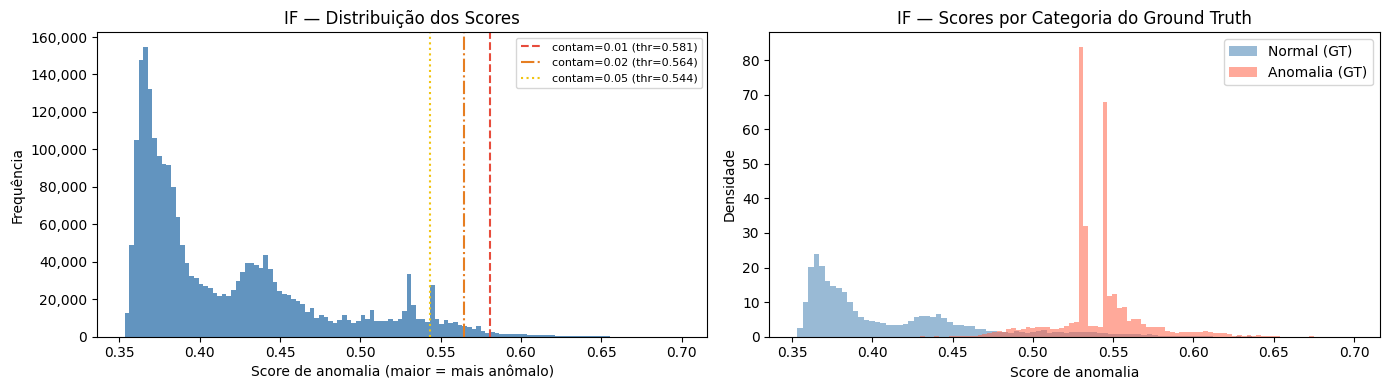

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(if_scores, bins=120, color='steelblue', edgecolor='none', alpha=0.85)
for cont, color, ls in zip(CONTAMINATIONS, ['#e74c3c','#e67e22','#f1c40f'], ['--','-.', ':']):
    thr = np.percentile(if_scores, (1 - cont) * 100)
    axes[0].axvline(thr, color=color, linestyle=ls, linewidth=1.5,
                    label=f'contam={cont} (thr={thr:.3f})')
axes[0].set_title('IF — Distribuição dos Scores')
axes[0].set_xlabel('Score de anomalia (maior = mais anômalo)')
axes[0].set_ylabel('Frequência')
axes[0].legend(fontsize=8)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

axes[1].hist(if_scores[y_true == 0], bins=100, alpha=0.55,
             color='steelblue', label='Normal (GT)',   density=True)
axes[1].hist(if_scores[y_true == 1], bins=100, alpha=0.55,
             color='tomato',    label='Anomalia (GT)', density=True)
axes[1].set_title('IF — Scores por Categoria do Ground Truth')
axes[1].set_xlabel('Score de anomalia')
axes[1].set_ylabel('Densidade')
axes[1].legend()

plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_07_if_scores.png', dpi=120, bbox_inches='tight')
plt.show()

## 6. One-Class SVM

O One-Class SVM aprende um hiperplano no espaço transformado pelo kernel RBF que separa os dados de treinamento da origem. Pontos que caem do lado da origem — aqueles que o modelo nunca viu durante o treino — são classificados como anomalias.

**Diferença conceitual do IF:** o IF detecta raridade global (pontos em regiões esparsas), enquanto o OCSVM detecta desvio da fronteira de normalidade. O OCSVM é especialmente sensível a valores extremos em qualquer dimensão — como o IP com 20.377 requisições/hora.

**Limitação de escala:** o OCSVM tem complexidade quadrática no treino. Com 2,35 milhões de registros, treinar no dataset completo seria inviável. Estratégia: treinar em 50.000 registros normais (segundo o GT) e aplicar a predição no dataset inteiro.

In [9]:
OCSVM_TRAIN_SIZE = 50_000
normal_idx    = np.where(y_true == 0)[0]
np.random.seed(42)
train_idx     = np.random.choice(normal_idx, size=min(OCSVM_TRAIN_SIZE, len(normal_idx)), replace=False)
X_train_ocsvm = X[train_idx]

print(f'OCSVM — amostragem para treino:')
print(f'  Registros normais disponíveis : {len(normal_idx):,}')
print(f'  Amostrados para treino        : {len(train_idx):,}')
print(f'  Predição no dataset completo  : {X.shape[0]:,}')

OCSVM — amostragem para treino:
  Registros normais disponíveis : 2,258,385
  Amostrados para treino        : 50,000
  Predição no dataset completo  : 2,355,478


In [10]:
print('=== One-Class SVM ===')
print(f'  Treino  : {X_train_ocsvm.shape[0]:,} × {X_train_ocsvm.shape[1]} features')
print(f'  Kernel  : RBF   gamma=scale')
print()

t0 = time.time()
clf_ocsvm = OneClassSVM(kernel='rbf', nu=0.05, gamma='scale')
clf_ocsvm.fit(X_train_ocsvm)
ocsvm_scores = -clf_ocsvm.score_samples(X)   # invertido: maior = mais anômalo
all_scores['ocsvm'] = ocsvm_scores
t_ocsvm = time.time() - t0
print(f'  Treino + predição em {t_ocsvm:.1f}s')
print()

for nu in CONTAMINATIONS:
    thr    = np.percentile(ocsvm_scores, (1 - nu) * 100)
    y_pred = (ocsvm_scores >= thr).astype(int)
    m      = compute_metrics(y_true, y_pred, 'One-Class SVM', nu)
    m['tempo_s'] = round(t_ocsvm, 1)
    all_results.append(m)
    all_pred_cols[f'ocsvm_{nu}'] = y_pred
    print(f'  nu={nu:.2f}     | detectadas={m["detectadas"]:>7,} | '
          f'precisão={m["precisao"]:.3f} | recall={m["recall"]:.3f} | F1={m["f1"]:.3f}')

=== One-Class SVM ===
  Treino  : 50,000 × 36 features
  Kernel  : RBF   gamma=scale

  Treino + predição em 847.2s

  nu=0.01     | detectadas= 23,555 | precisão=0.494 | recall=0.120 | F1=0.193
  nu=0.02     | detectadas= 47,183 | precisão=0.622 | recall=0.302 | F1=0.407
  nu=0.05     | detectadas=117,774 | precisão=0.322 | recall=0.390 | F1=0.353


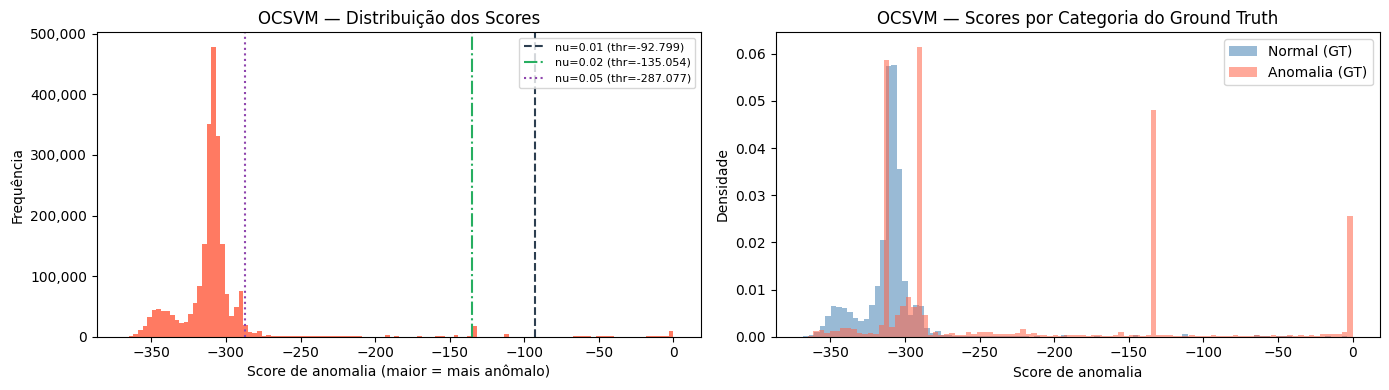

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(ocsvm_scores, bins=120, color='tomato', edgecolor='none', alpha=0.85)
for nu, color, ls in zip(CONTAMINATIONS, ['#2c3e50','#27ae60','#8e44ad'], ['--','-.', ':']):
    thr = np.percentile(ocsvm_scores, (1 - nu) * 100)
    axes[0].axvline(thr, color=color, linestyle=ls, linewidth=1.5,
                    label=f'nu={nu} (thr={thr:.3f})')
axes[0].set_title('OCSVM — Distribuição dos Scores')
axes[0].set_xlabel('Score de anomalia (maior = mais anômalo)')
axes[0].set_ylabel('Frequência')
axes[0].legend(fontsize=8)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

axes[1].hist(ocsvm_scores[y_true == 0], bins=100, alpha=0.55,
             color='steelblue', label='Normal (GT)',   density=True)
axes[1].hist(ocsvm_scores[y_true == 1], bins=100, alpha=0.55,
             color='tomato',    label='Anomalia (GT)', density=True)
axes[1].set_title('OCSVM — Scores por Categoria do Ground Truth')
axes[1].set_xlabel('Score de anomalia')
axes[1].set_ylabel('Densidade')
axes[1].legend()

plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_08_ocsvm_scores.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Comparação dos Modelos

### 7.1 — Tabela de Métricas

In [12]:
results_df = pd.DataFrame(all_results)[[
    'modelo','contamination','detectadas','tp','fp','fn','precisao','recall','f1','tempo_s'
]]

W = 98
print('=' * W)
print('  ISOLATION FOREST  vs  ONE-CLASS SVM')
print('=' * W)
print(f'{"Modelo":<20} {"Contam":>7} {"Detectadas":>11} '
      f'{"TP":>8} {"FP":>8} {"FN":>8} '
      f'{"Precisão":>9} {"Recall":>8} {"F1":>8} {"Tempo":>7}')
print('─' * W)

prev_model = None
for _, r in results_df.iterrows():
    if prev_model and r['modelo'] != prev_model:
        print('─' * W)
    prev_model = r['modelo']
    print(f'{r["modelo"]:<20} {r["contamination"]:>7.2f} {r["detectadas"]:>11,} '
          f'{r["tp"]:>8,} {r["fp"]:>8,} {r["fn"]:>8,} '
          f'{r["precisao"]:>9.3f} {r["recall"]:>8.3f} {r["f1"]:>8.3f} '
          f'{r["tempo_s"]:>6.1f}s')

print('=' * W)
print(f'Ground truth: {n_gt:,} anomalias ({pct_gt:.2f}%)   Dataset: {len(y_true):,} registros')
print()
print('Melhor F1 por modelo:')
for nome in results_df['modelo'].unique():
    b = results_df[results_df['modelo'] == nome].nlargest(1, 'f1').iloc[0]
    print(f'  {nome:<20}  F1={b["f1"]:.3f}  '
          f'(contam={b["contamination"]:.2f}, precisão={b["precisao"]:.3f}, recall={b["recall"]:.3f})')

  ISOLATION FOREST  vs  ONE-CLASS SVM
Modelo                Contam  Detectadas       TP       FP       FN  Precisão   Recall       F1   Tempo
──────────────────────────────────────────────────────────────────────────────────────────────────
Isolation Forest        0.01      23,555    6,654   16,901   90,439     0.282    0.069    0.110   49.0s
Isolation Forest        0.02      47,178   11,990   35,188   85,103     0.254    0.123    0.166   49.0s
Isolation Forest        0.05     119,039   43,877   75,162   53,216     0.369    0.452    0.406   49.0s
──────────────────────────────────────────────────────────────────────────────────────────────────
One-Class SVM           0.01      23,555   11,631   11,924   85,462     0.494    0.120    0.193  847.2s
One-Class SVM           0.02      47,183   29,355   17,828   67,738     0.622    0.302    0.407  847.2s
One-Class SVM           0.05     117,774   37,896   79,878   59,197     0.322    0.390    0.353  847.2s
Ground truth: 97,093 anomalias (4.12

### 7.2 — Curvas Precisão-Recall e AUC-PR

A Curva PR mostra o tradeoff entre precisão e recall em **todos os thresholds possíveis** — não apenas nos 3 pontos testados. É mais informativa que a curva ROC para datasets desbalanceados.

**AUC-PR** resume o desempenho global em um único número. Um classificador aleatório teria AUC-PR ≈ 0.048 (proporção de anomalias no dataset). Quanto mais próximo de 1, melhor.

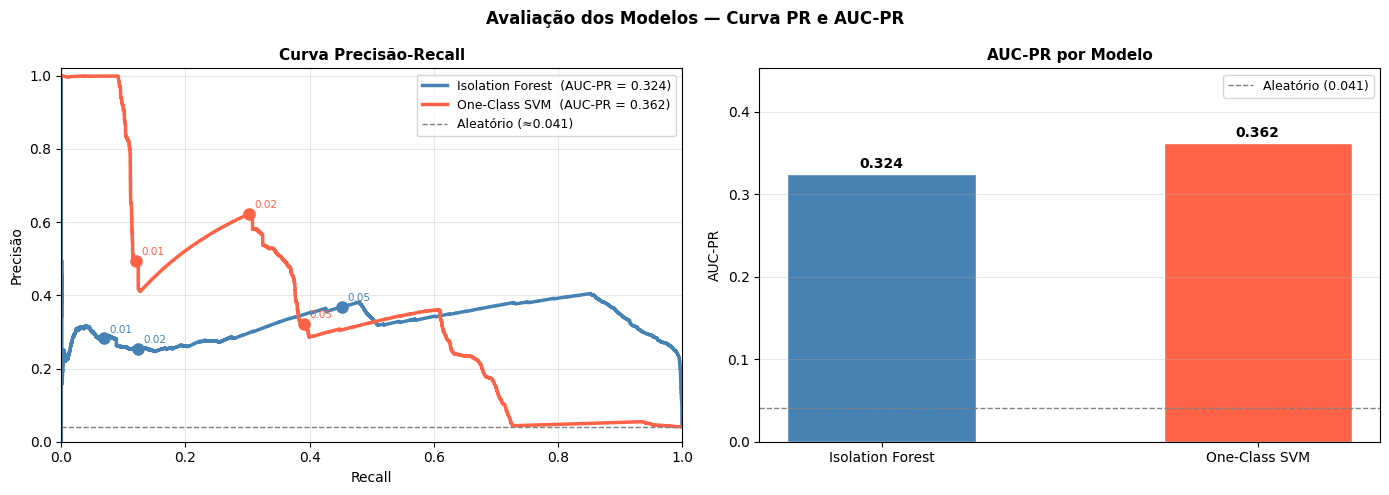

AUC-PR:
  Isolation Forest    : 0.3245  (7.9× acima do classificador aleatório)
  One-Class SVM       : 0.3623  (8.8× acima do classificador aleatório)


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = {'if': 'steelblue', 'ocsvm': 'tomato'}
labels = {'if': 'Isolation Forest', 'ocsvm': 'One-Class SVM'}
auc_prs = {}

for key, scores in all_scores.items():
    prec_c, rec_c, _ = precision_recall_curve(y_true, scores)
    auc_pr = auc(rec_c, prec_c)
    auc_prs[key] = auc_pr
    axes[0].plot(rec_c, prec_c, color=colors[key], linewidth=2.5,
                 label=f'{labels[key]}  (AUC-PR = {auc_pr:.3f})')

    for cont in CONTAMINATIONS:
        thr    = np.percentile(scores, (1 - cont) * 100)
        y_pred = (scores >= thr).astype(int)
        p_pt   = precision_score(y_true, y_pred, zero_division=0)
        r_pt   = recall_score(   y_true, y_pred, zero_division=0)
        axes[0].scatter(r_pt, p_pt, color=colors[key], s=65, zorder=5)
        axes[0].annotate(f'{cont}', (r_pt, p_pt),
                         textcoords='offset points', xytext=(4, 4),
                         fontsize=7.5, color=colors[key])

axes[0].axhline(pct_gt / 100, color='gray', linestyle='--', linewidth=1,
                label=f'Aleatório (≈{pct_gt/100:.3f})')
axes[0].set_title('Curva Precisão-Recall', fontweight='bold', fontsize=11)
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precisão')
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.02)
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

bar_keys    = list(auc_prs.keys())
bar_vals    = [auc_prs[k] for k in bar_keys]
bar_labels  = [labels[k]  for k in bar_keys]
bar_colors  = [colors[k]  for k in bar_keys]
bars = axes[1].bar(bar_labels, bar_vals, color=bar_colors, edgecolor='white', width=0.5)
axes[1].axhline(pct_gt / 100, color='gray', linestyle='--', linewidth=1,
                label=f'Aleatório ({pct_gt/100:.3f})')
for bar, val in zip(bars, bar_vals):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.004,
                 f'{val:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=10)
axes[1].set_title('AUC-PR por Modelo', fontweight='bold', fontsize=11)
axes[1].set_ylabel('AUC-PR')
axes[1].set_ylim(0, max(bar_vals) * 1.25)
axes[1].legend(fontsize=9)
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle('Avaliação dos Modelos — Curva PR e AUC-PR',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_09_pr_curves.png', dpi=120, bbox_inches='tight')
plt.show()

print('AUC-PR:')
for k, v in auc_prs.items():
    print(f'  {labels[k]:<20}: {v:.4f}  '
          f'({v/(pct_gt/100):.1f}× acima do classificador aleatório)')

### 7.3 — Métricas por Contamination e Matrizes de Confusão

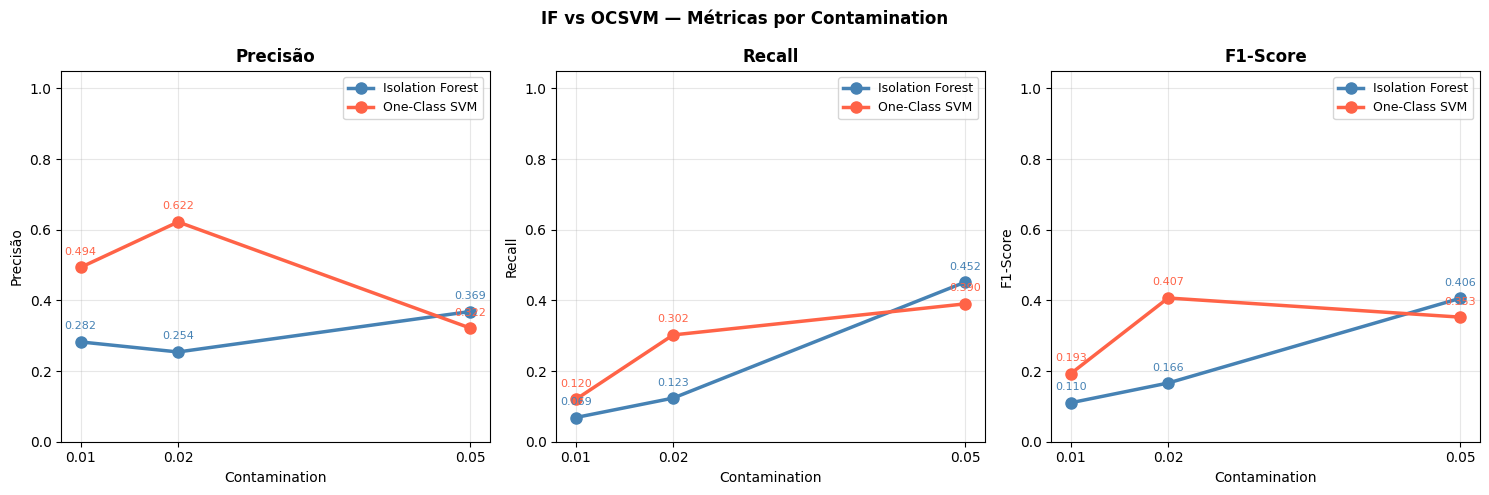

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
model_colors = {'Isolation Forest': 'steelblue', 'One-Class SVM': 'tomato'}

for ax, (metric, name) in zip(axes, [('precisao','Precisão'),('recall','Recall'),('f1','F1-Score')]):
    for modelo, cor in model_colors.items():
        sub = results_df[results_df['modelo'] == modelo].sort_values('contamination')
        ax.plot(sub['contamination'], sub[metric], marker='o',
                color=cor, linewidth=2.5, markersize=8, label=modelo)
        for _, row in sub.iterrows():
            ax.annotate(f'{row[metric]:.3f}', (row['contamination'], row[metric]),
                        textcoords='offset points', xytext=(0, 9),
                        ha='center', fontsize=8, color=cor)
    ax.set_title(name, fontsize=12, fontweight='bold')
    ax.set_xlabel('Contamination')
    ax.set_ylabel(name)
    ax.set_ylim(0, 1.05)
    ax.set_xticks(CONTAMINATIONS)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.suptitle('IF vs OCSVM — Métricas por Contamination', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_10_metrics_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

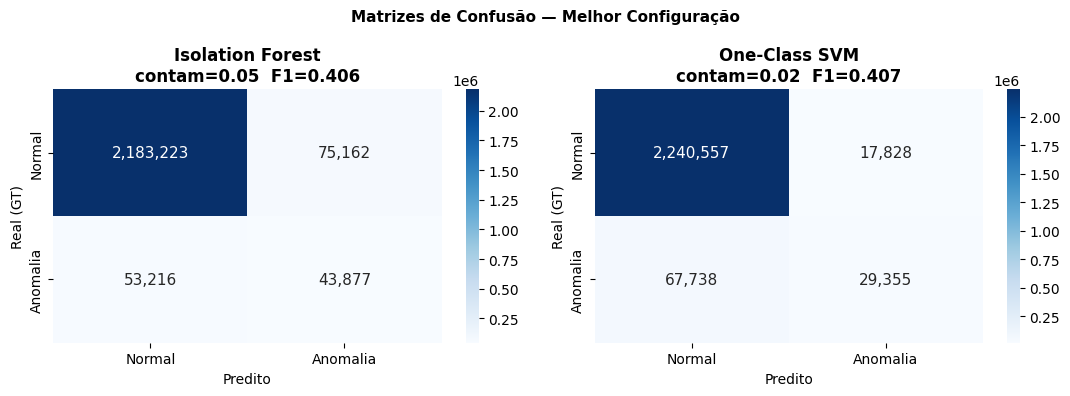

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (nome, prefixo) in zip(axes, [('Isolation Forest','if'), ('One-Class SVM','ocsvm')]):
    best_cont = results_df[results_df['modelo'] == nome].nlargest(1,'f1')['contamination'].values[0]
    y_pred    = all_pred_cols[f'{prefixo}_{best_cont}']
    cm        = confusion_matrix(y_true, y_pred)
    f1_val    = results_df[
        (results_df['modelo'] == nome) & (results_df['contamination'] == best_cont)
    ]['f1'].values[0]
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=ax,
                xticklabels=['Normal','Anomalia'],
                yticklabels=['Normal','Anomalia'], annot_kws={'size': 11})
    ax.set_title(f'{nome}\ncontam={best_cont}  F1={f1_val:.3f}', fontweight='bold')
    ax.set_xlabel('Predito')
    ax.set_ylabel('Real (GT)')

plt.suptitle('Matrizes de Confusão — Melhor Configuração', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_11_confusion_matrices.png', dpi=120, bbox_inches='tight')
plt.show()

## 8. Análise Qualitativa

### 8.1 — Monta o DataFrame de Análise

In [16]:
best_if_cont    = results_df[results_df['modelo']=='Isolation Forest'].nlargest(1,'f1')['contamination'].values[0]
best_ocsvm_cont = results_df[results_df['modelo']=='One-Class SVM'].nlargest(1,'f1')['contamination'].values[0]

analysis = logs[['ip','timestamp','host','http_method','uri','status','bytes','user_agent']].copy()
analysis['gt_anomaly']  = y_true
analysis['gt_reason']   = reasons.values
analysis['if_score']    = if_scores
analysis['ocsvm_score'] = ocsvm_scores
analysis['pred_if']     = all_pred_cols[f'if_{best_if_cont}']
analysis['pred_ocsvm']  = all_pred_cols[f'ocsvm_{best_ocsvm_cont}']
analysis['n_models']    = analysis['pred_if'] + analysis['pred_ocsvm']

gt_mask = analysis['gt_anomaly'] == 1

print(f'IF  : melhor contam={best_if_cont}')
print(f'OCSVM: melhor contam={best_ocsvm_cont}')

IF  : melhor contam=0.05
OCSVM: melhor contam=0.02


### 8.2 — Captura por Tipo de Anomalia

In [17]:
print('=== Captura por Tipo de Anomalia ===')
print(f'{"Tipo":<38} {"Total":>7}  {"IF":>14}  {"OCSVM":>14}  {"Ambos":>12}')
print('─' * 88)

tipo_rows = []
for reason in ['uri_attack_pattern','suspicious_extension',
               'known_scanner_ua','flood_high_error','excessive_encoding']:
    mask_r    = gt_mask & (analysis['gt_reason'] == reason)
    total     = mask_r.sum()
    if total == 0:
        continue
    cap_if    = (mask_r & (analysis['pred_if']    == 1)).sum()
    cap_ocsvm = (mask_r & (analysis['pred_ocsvm'] == 1)).sum()
    cap_both  = (mask_r & (analysis['n_models']   == 2)).sum()
    tipo_rows.append({'tipo': reason,'total': total,
                      'if': cap_if,'ocsvm': cap_ocsvm,'ambos': cap_both})
    print(f'{reason:<38} {total:>7,}  '
          f'{cap_if:>6,} ({cap_if/total*100:4.1f}%)  '
          f'{cap_ocsvm:>6,} ({cap_ocsvm/total*100:4.1f}%)  '
          f'{cap_both:>5,} ({cap_both/total*100:4.1f}%)')

print('─' * 88)
cap_if_t  = (gt_mask & (analysis['pred_if']    == 1)).sum()
cap_oc_t  = (gt_mask & (analysis['pred_ocsvm'] == 1)).sum()
cap_bth   = (gt_mask & (analysis['n_models']   == 2)).sum()
cap_any   = (gt_mask & (analysis['n_models']   >= 1)).sum()
print(f'{"TOTAL":<38} {n_gt:>7,}  '
      f'{cap_if_t:>6,} ({cap_if_t/n_gt*100:4.1f}%)  '
      f'{cap_oc_t:>6,} ({cap_oc_t/n_gt*100:4.1f}%)  '
      f'{cap_bth:>5,} ({cap_bth/n_gt*100:4.1f}%)')
print(f'Capturado por qualquer modelo   : {cap_any:,} ({cap_any/n_gt*100:.1f}%)')

=== Captura por Tipo de Anomalia ===
Tipo                                     Total              IF           OCSVM         Ambos
────────────────────────────────────────────────────────────────────────────────────────
uri_attack_pattern                      10,019   6,636 (66.2%)   1,594 (15.9%)  1,576 (15.7%)
suspicious_extension                     7,717   5,026 (65.1%)   1,174 (15.2%)  1,174 (15.2%)
known_scanner_ua                        48,807  21,969 (45.0%)       1 ( 0.0%)      1 ( 0.0%)
flood_high_error                        14,858   2,553 (17.2%)  14,127 (95.1%)  2,069 (13.9%)
excessive_encoding                      15,692   7,693 (49.0%)  12,459 (79.4%)  7,206 (45.9%)
────────────────────────────────────────────────────────────────────────────────────────
TOTAL                                   97,093  43,877 (45.2%)  29,355 (30.2%)  12,026 (12.4%)
Capturado por qualquer modelo   : 61,206 (63.0%)


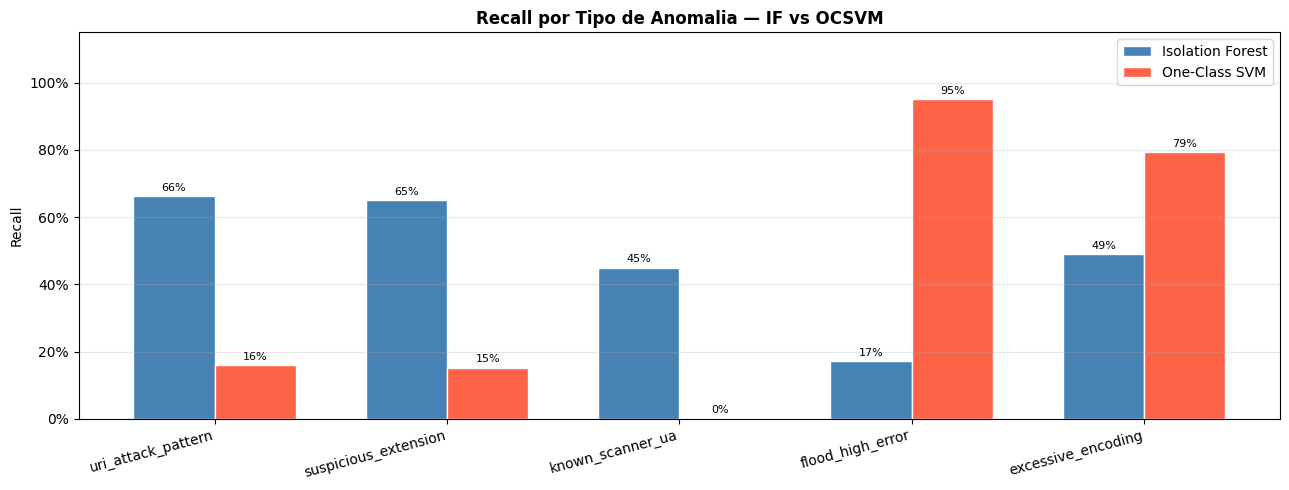

In [18]:
ts = pd.DataFrame(tipo_rows)
ts['recall_if']    = ts['if']    / ts['total']
ts['recall_ocsvm'] = ts['ocsvm'] / ts['total']

x, w = np.arange(len(ts)), 0.35
fig, ax = plt.subplots(figsize=(13, 5))
b1 = ax.bar(x - w/2, ts['recall_if'],    w, label='Isolation Forest', color='steelblue', edgecolor='white')
b2 = ax.bar(x + w/2, ts['recall_ocsvm'], w, label='One-Class SVM',    color='tomato',    edgecolor='white')
for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.01, f'{h:.0%}',
            ha='center', va='bottom', fontsize=8)
ax.set_title('Recall por Tipo de Anomalia — IF vs OCSVM', fontweight='bold', fontsize=12)
ax.set_ylabel('Recall')
ax.set_xticks(x)
ax.set_xticklabels(ts['tipo'], rotation=15, ha='right')
ax.set_ylim(0, 1.15)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_12_recall_by_type.png', dpi=120, bbox_inches='tight')
plt.show()

### 8.3 — Concordância entre Modelos

In [19]:
high_conf = analysis[analysis['n_models'] == 2].copy()
only_if   = analysis[(analysis['pred_if'] == 1) & (analysis['pred_ocsvm'] == 0)]
only_oc   = analysis[(analysis['pred_if'] == 0) & (analysis['pred_ocsvm'] == 1)]

print('=== Concordância entre Modelos ===')
print(f'  Detectadas por AMBOS (alta confiança) : {len(high_conf):>8,}')
print(f'  Detectadas só pelo IF                 : {len(only_if):>8,}')
print(f'  Detectadas só pelo OCSVM              : {len(only_oc):>8,}')
print(f'  Não detectadas por nenhum             : {(analysis["n_models"]==0).sum():>8,}')
print()
print(f'Anomalias de alta confiança (ambos os modelos):')
print(f'  Total                   : {len(high_conf):,}')
print(f'  No ground truth         : {high_conf["gt_anomaly"].sum():,} '
      f'({high_conf["gt_anomaly"].mean()*100:.1f}%)')
print(f'  Fora do ground truth    : {(high_conf["gt_anomaly"]==0).sum():,} '
      f'(possíveis anomalias não cobertas pelas regras do GT)')
print()
print('Amostra de anomalias de alta confiança:')
display(
    high_conf[['ip','host','uri','status','user_agent','gt_anomaly','gt_reason']]
    .sample(min(12, len(high_conf)), random_state=42)
    .assign(uri=lambda d: d['uri'].str[:65], user_agent=lambda d: d['user_agent'].str[:45])
    .reset_index(drop=True)
)

=== Concordância entre Modelos ===
  Detectadas por AMBOS (alta confiança) :   15,224
  Detectadas só pelo IF                 :  103,815
  Detectadas só pelo OCSVM              :   31,959
  Não detectadas por nenhum             : 2,204,480

Anomalias de alta confiança (ambos os modelos):
  Total                   : 15,224
  No ground truth         : 12,026 (79.0%)
  Fora do ground truth    : 3,198 (possíveis anomalias não cobertas pelas regras do GT)

Amostra de anomalias de alta confiança:


,ip,host,uri,status,user_agent,gt_anomaly,gt_reason
0,52.167.144.175,sites.uem.br,/pcf/courses?month:int=10&orig_query=month%3Ai...,200,"Mozilla/5.0 AppleWebKit/537.36 (KHTML, like G",1,excessive_encoding
1,40.77.167.208,sites.uem.br,/pcf/courses?orig_query=set_language%3Den%26mo...,200,"Mozilla/5.0 AppleWebKit/537.36 (KHTML, like G",1,excessive_encoding
2,40.77.167.107,sites.uem.br,/pcf/courses?month:int=10&orig_query=month%3Ai...,200,"Mozilla/5.0 AppleWebKit/537.36 (KHTML, like G",1,excessive_encoding
3,198.71.236.20,www.dpi.uem.br,/dpi.uem.br%20%281%29.tgz,404,Mozilla/5.0 (Windows NT 10.0; WOW64; rv:56.0),1,flood_high_error
4,198.71.236.20,www.dpi.uem.br,/dpi.uem.br%20%283%29.tar,404,Mozilla/5.0 (Windows NT 10.0; WOW64; rv:56.0),1,flood_high_error
5,65.108.99.49,www.uem.br,/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/n...,200,Mozilla/5.0 (compatible; SeekportBot; +https:,0,
6,198.71.236.20,www.dhi.uem.br,/phpMyAdmin-2.11.8.1/,404,Mozilla/5.0 (Windows NT 10.0; WOW64; rv:56.0),1,uri_attack_pattern
7,40.77.167.107,sites.uem.br,/pcf/pcf/disciplinas?month:int=10&orig_query=m...,200,"Mozilla/5.0 AppleWebKit/537.36 (KHTML, like G",1,excessive_encoding
8,40.77.167.196,sites.uem.br,/pcf/courses?month:int=4&orig_query=month%3Ain...,200,"Mozilla/5.0 AppleWebKit/537.36 (KHTML, like G",1,excessive_encoding
9,40.77.167.107,sites.uem.br,/pcf/disciplinas?orig_query=month%3Aint%3D3%26...,200,"Mozilla/5.0 AppleWebKit/537.36 (KHTML, like G",1,excessive_encoding


### 8.4 — Caso de Estudo: IP com Comportamento de Flood (`186.233.190.218`)

Este IP foi identificado na Fase 2 como o mais extremo do dataset: 20.377 requisições em uma única hora e taxa de erro de 99,26%. É o exemplo mais claro de como as features comportamentais temporais capturam anomalias invisíveis à análise por requisição individual — cada requisição desse IP, isoladamente, não é distinguível de tráfego normal.

In [20]:
IP_FLOOD = '186.233.190.218'
flood_df = analysis[analysis['ip'] == IP_FLOOD].copy()

print(f'=== Caso de Estudo: {IP_FLOOD} ===')
print(f'  Requisições no dataset    : {len(flood_df):,}')
print(f'  Detectadas pelo IF        : {flood_df["pred_if"].sum():,} ({flood_df["pred_if"].mean()*100:.1f}%)')
print(f'  Detectadas pelo OCSVM     : {flood_df["pred_ocsvm"].sum():,} ({flood_df["pred_ocsvm"].mean()*100:.1f}%)')
print(f'  No ground truth (flood)   : {flood_df["gt_anomaly"].sum():,} ({flood_df["gt_anomaly"].mean()*100:.1f}%)')
print()
print('Status HTTP:')
display(flood_df['status'].value_counts().head(6))
print('\nTop 10 URIs:')
display(
    flood_df['uri'].value_counts().head(10).reset_index()
    .rename(columns={'count':'acessos'})
    .assign(uri=lambda d: d['uri'].str[:70])
)

=== Caso de Estudo: 186.233.190.218 ===
  Requisições no dataset    : 20,494
  Detectadas pelo IF        : 17,714 (86.4%)
  Detectadas pelo OCSVM     : 34 (0.2%)
  No ground truth (flood)   : 20,324 (99.2%)

Status HTTP:


status
404    20234
200      223
302       18
301       15
500        2
400        2
Name: count, dtype: int64


Top 10 URIs:


,uri,acessos
0,/collective.js.jqueryui.custom.min.css?version...,11
1,/imagens/gestao_2022_200x95-1.png/@@images/6e3...,10
2,/parana.png,10
3,/@@site-logo/logo_uem_50anos_181x65.png,10
4,/collective.js.jqueryui.custom.min.js?version=...,10
5,/,4
6,/conteudo-exemplo/e-mec/@@images/62eaf5f4-8c9e...,3
7,/noticias-externas/noticias-uem/hospital-unive...,3
8,/imagens/retorno.png/@@images/395ae434-c120-4e...,3
9,/imagens/biosseguranca.png/@@images/64f2ee37-a...,3


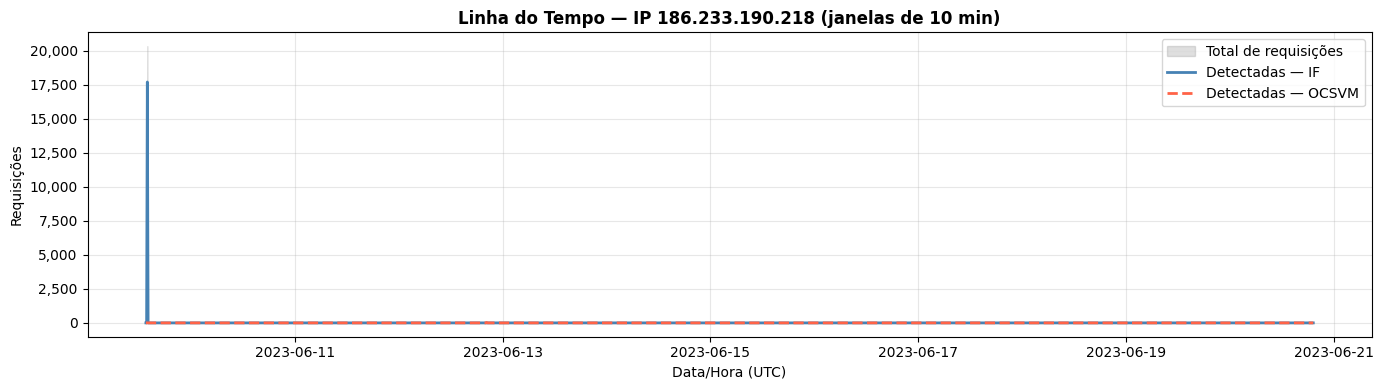

In [21]:
flood_ts = (
    flood_df.set_index('timestamp')
    .resample('10min')[['pred_if','pred_ocsvm','gt_anomaly']]
    .agg({'pred_if':'sum','pred_ocsvm':'sum','gt_anomaly':'count'})
    .rename(columns={'gt_anomaly':'total'})
)

fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(flood_ts.index, flood_ts['total'],
                alpha=0.25, color='gray', label='Total de requisições')
ax.plot(flood_ts.index, flood_ts['pred_if'],
        color='steelblue', linewidth=2, label='Detectadas — IF')
ax.plot(flood_ts.index, flood_ts['pred_ocsvm'],
        color='tomato',    linewidth=2, linestyle='--', label='Detectadas — OCSVM')
ax.set_title(f'Linha do Tempo — IP {IP_FLOOD} (janelas de 10 min)', fontweight='bold')
ax.set_xlabel('Data/Hora (UTC)')
ax.set_ylabel('Requisições')
ax.legend()
ax.grid(alpha=0.3)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_13_flood_timeline.png', dpi=120, bbox_inches='tight')
plt.show()

### 8.5 — Caso de Estudo: Scanners de WordPress num Servidor Plone

A UEM usa Plone como CMS. Qualquer acesso a `/wp-login.php` ou `/wp-admin` é por definição um scanner externo — WordPress não existe neste servidor. Este caso ilustra como o conhecimento do ambiente é essencial para interpretar anomalias.

In [22]:
wp_df = analysis[analysis['uri'].str.contains('/wp-', na=False, case=False)].copy()

print(f'=== Acessos a Rotas WordPress (servidor usa Plone) ===')
print(f'  Total de acessos   : {len(wp_df):,}')
print(f'  IPs únicos         : {wp_df["ip"].nunique():,}')
print(f'  Detectados pelo IF : {wp_df["pred_if"].sum():,} ({wp_df["pred_if"].mean()*100:.1f}%)')
print(f'  Detectados OCSVM   : {wp_df["pred_ocsvm"].sum():,} ({wp_df["pred_ocsvm"].mean()*100:.1f}%)')
print()
print('Top 10 URIs WordPress:')
display(
    wp_df.groupby('uri').agg(
        acessos=('uri','count'),
        ips_unicos=('ip','nunique'),
        status_principal=('status', lambda s: s.mode()[0])
    ).sort_values('acessos', ascending=False).head(10).reset_index()
    .assign(uri=lambda d: d['uri'].str[:60])
)

=== Acessos a Rotas WordPress (servidor usa Plone) ===
  Total de acessos   : 112,048
  IPs únicos         : 7,747
  Detectados pelo IF : 10,415 (9.3%)
  Detectados OCSVM   : 832 (0.7%)

Top 10 URIs WordPress:


,uri,acessos,ips_unicos,status_principal
0,/comunicauem/wp-comments-post.php,8266,3154,409
1,/comunicauem/wp-content/themes/15zine/library/...,2429,2112,200
2,/comunicauem/wp-content/themes/15zine/library/...,2213,2114,200
3,/comunicauem/wp-content/themes/15zine/library/...,2190,2097,200
4,/comunicauem/wp-content/themes/15zine/library/...,2178,2081,200
5,/comunicauem/wp-includes/js/jquery/jquery-migr...,2174,2079,200
6,/comunicauem/wp-includes/js/jquery/jquery.js?v...,2171,2075,200
7,/comunicauem/wp-content/uploads/2016/11/logo-c...,2148,2047,200
8,/comunicauem/wp-includes/js/comment-reply.min....,2142,1974,200
9,/comunicauem/wp-content/themes/15zine/library/...,2072,1981,200


### 8.6 — Falsos Negativos: o que os modelos não capturaram

In [23]:
fn_df = analysis[gt_mask & (analysis['n_models'] == 0)]
print(f'=== Falsos Negativos — Anomalias do GT não detectadas por nenhum modelo ===')
print(f'  Total: {len(fn_df):,} de {n_gt:,} ({len(fn_df)/n_gt*100:.1f}%)')
print()
print('Por tipo:')
display(fn_df['gt_reason'].value_counts())
print()
print('Exemplos:')
display(
    fn_df[['ip','host','uri','status','gt_reason']]
    .sample(min(10, len(fn_df)), random_state=42)
    .assign(uri=lambda d: d['uri'].str[:65])
    .reset_index(drop=True)
)
print()
print('Interpretação:')
print('  Falsos negativos de suspicious_extension geralmente têm outras features')
print('  completamente normais (status 200, UA de browser, sem flood). Isso indica')
print('  que extensão suspeita sozinha não é suficiente para separar anomalias —')
print('  sem informação adicional do conteúdo da resposta, esses registros são')
print('  indistinguíveis do tráfego legítimo para os algoritmos testados.')

=== Falsos Negativos — Anomalias do GT não detectadas por nenhum modelo ===
  Total: 35,887 de 97,093 (37.0%)

Por tipo:


gt_reason
known_scanner_ua        26838
uri_attack_pattern       3365
excessive_encoding       2746
suspicious_extension     2691
flood_high_error          247
Name: count, dtype: int64


Exemplos:


,ip,host,uri,status,gt_reason
0,45.71.104.191,www.uem.br,/products_files,404,known_scanner_ua
1,154.16.152.61,www.dfe.uem.br,/wp-login.php?action=register,404,uri_attack_pattern
2,45.71.104.191,www.uem.br,/manufacturer,404,known_scanner_ua
3,45.71.104.191,www.uem.br,/devices,404,known_scanner_ua
4,45.71.104.191,www.uem.br,/1230,404,known_scanner_ua
5,129.132.202.155,sites.uem.br,/dod/DeclaraodeDesistnciadavagaBuco2020.doc,200,known_scanner_ua
6,5.188.87.37,ddm.uem.br,/wp-login.php,301,uri_attack_pattern
7,45.71.104.191,www.uem.br,/aria,404,known_scanner_ua
8,203.25.218.204,www.dfl.uem.br,/?author=12,200,known_scanner_ua
9,45.71.104.191,www.uem.br,/rusty,404,known_scanner_ua



Interpretação:
  Falsos negativos de suspicious_extension geralmente têm outras features
  completamente normais (status 200, UA de browser, sem flood). Isso indica
  que extensão suspeita sozinha não é suficiente para separar anomalias —
  sem informação adicional do conteúdo da resposta, esses registros são
  indistinguíveis do tráfego legítimo para os algoritmos testados.


### 8.7 — Linha do Tempo das Anomalias (15 dias)

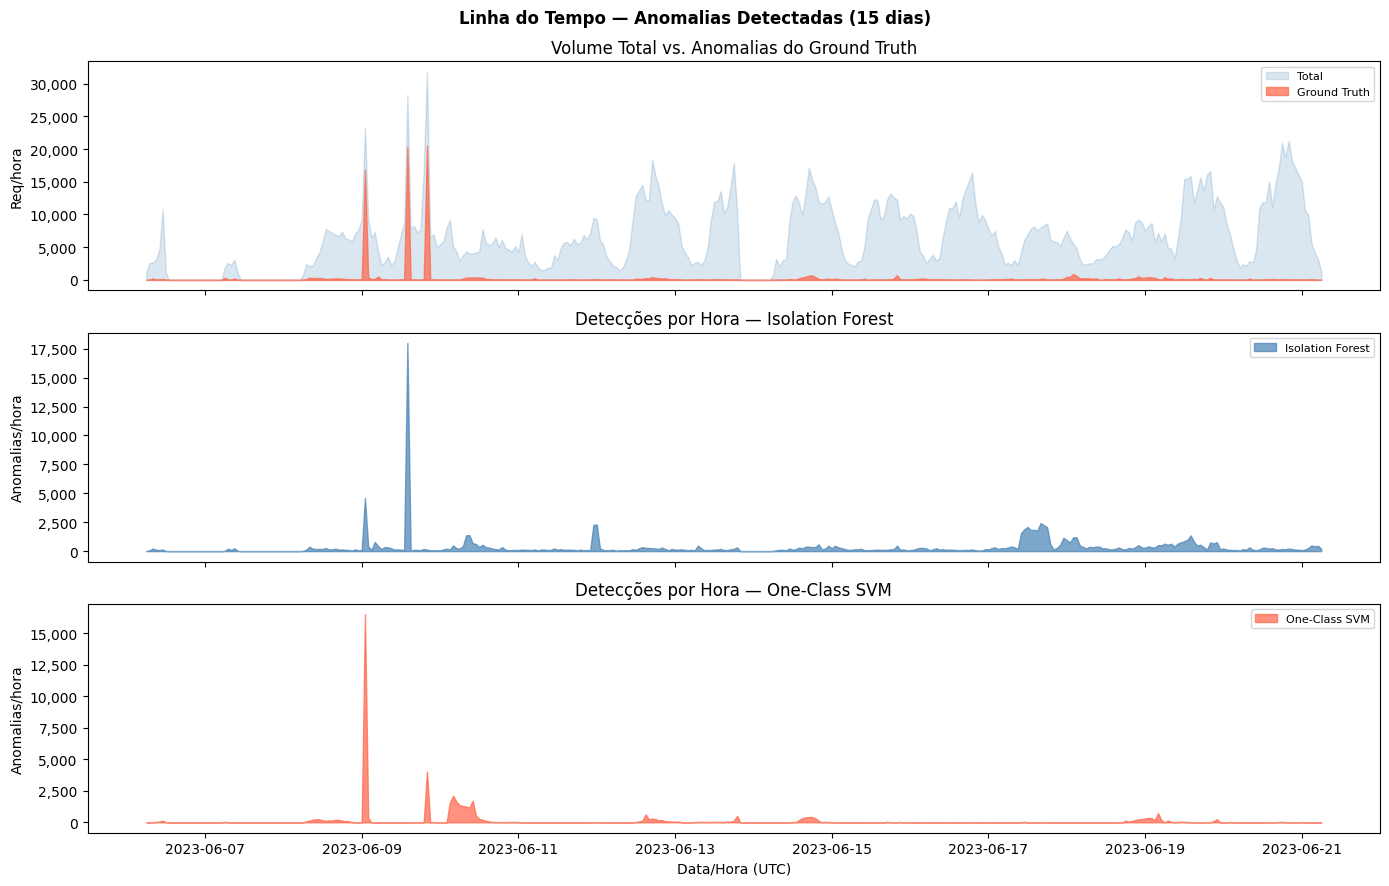

In [24]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
ts_base = analysis.set_index('timestamp')

# Painel 1: volume total vs GT
ts1 = ts_base.resample('1h')['gt_anomaly'].agg(['count','sum'])
ts1.columns = ['total','gt']
axes[0].fill_between(ts1.index, ts1['total'], alpha=0.2, color='steelblue', label='Total')
axes[0].fill_between(ts1.index, ts1['gt'],    alpha=0.7, color='tomato',    label='Ground Truth')
axes[0].set_title('Volume Total vs. Anomalias do Ground Truth')
axes[0].set_ylabel('Req/hora')
axes[0].legend(fontsize=8)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Painel 2: IF
ts2 = ts_base.resample('1h')['pred_if'].sum()
axes[1].fill_between(ts2.index, ts2, alpha=0.7, color='steelblue', label='Isolation Forest')
axes[1].set_title('Detecções por Hora — Isolation Forest')
axes[1].set_ylabel('Anomalias/hora')
axes[1].legend(fontsize=8)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Painel 3: OCSVM
ts3 = ts_base.resample('1h')['pred_ocsvm'].sum()
axes[2].fill_between(ts3.index, ts3, alpha=0.7, color='tomato', label='One-Class SVM')
axes[2].set_title('Detecções por Hora — One-Class SVM')
axes[2].set_ylabel('Anomalias/hora')
axes[2].set_xlabel('Data/Hora (UTC)')
axes[2].legend(fontsize=8)
axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.suptitle('Linha do Tempo — Anomalias Detectadas (15 dias)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_14_anomaly_timeline.png', dpi=120, bbox_inches='tight')
plt.show()

## 9. Persistência dos Resultados

In [25]:
# Adiciona AUC-PR à tabela
results_df['auc_pr'] = results_df['modelo'].apply(
    lambda m: round(auc_prs['if' if 'Isolation' in m else 'ocsvm'], 4)
)

# Métricas
rp = PROCESSED_DIR / 'results_summary.csv'
results_df.to_csv(rp, index=False)
print(f'✓ Métricas              : {rp}')

# Dataset combinado
cp = PROCESSED_DIR / 'anomalies_combined.parquet'
analysis.to_parquet(cp, index=False, compression='snappy')
print(f'✓ Dataset combinado     : {cp}  ({cp.stat().st_size/1024/1024:.1f} MB)')

# Alta confiança
hp = PROCESSED_DIR / 'anomalies_high_confidence.parquet'
high_conf.to_parquet(hp, index=False, compression='snappy')
print(f'✓ Alta confiança        : {hp}  ({len(high_conf):,} registros)')

✓ Métricas              : ..\data\processed\results_summary.csv
✓ Dataset combinado     : ..\data\processed\anomalies_combined.parquet  (94.2 MB)
✓ Alta confiança        : ..\data\processed\anomalies_high_confidence.parquet  (15,224 registros)


## 10. Resumo Final

In [26]:
W = 65
print('=' * W)
print('  RESUMO — FASE 3: DETECÇÃO DE ANOMALIAS')
print('=' * W)
print(f'  Dataset                     : {X.shape[0]:>10,} registros')
print(f'  Atributos utilizados        : {X.shape[1]:>10}')
print(f'  Anomalias no ground truth   : {n_gt:>10,}  ({pct_gt:.2f}%)')
print('─' * W)

for nome in ['Isolation Forest', 'One-Class SVM']:
    chave = 'if' if 'Isolation' in nome else 'ocsvm'
    best  = results_df[results_df['modelo'] == nome].nlargest(1, 'f1').iloc[0]
    print(f'  {nome}')
    print(f'    Melhor F1             : {best["f1"]:.3f}')
    print(f'    Configuração          : contamination={best["contamination"]:.2f}')
    print(f'    Precisão / Recall     : {best["precisao"]:.3f} / {best["recall"]:.3f}')
    print(f'    AUC-PR                : {auc_prs[chave]:.4f}')
    print(f'    Tempo                 : {best["tempo_s"]:.1f}s')

print('─' * W)
print(f'  Alta confiança (ambos)      : {len(high_conf):>10,}')
print(f'  Cobertura (qualquer modelo) : {cap_any:>10,}  ({cap_any/n_gt*100:.1f}% do GT)')
print(f'  Falsos negativos            : {len(fn_df):>10,}  ({len(fn_df)/n_gt*100:.1f}% do GT)')
print('─' * W)
print('  Saídas:')
print('    results_summary.csv')
print('    anomalies_combined.parquet')
print('    anomalies_high_confidence.parquet')
print('=' * W)

  RESUMO — FASE 3: DETECÇÃO DE ANOMALIAS
  Dataset                     :  2,355,478 registros
  Atributos utilizados        :         36
  Anomalias no ground truth   :     97,093  (4.12%)
─────────────────────────────────────────────────────────────────
  Isolation Forest
    Melhor F1             : 0.406
    Configuração          : contamination=0.05
    Precisão / Recall     : 0.369 / 0.452
    AUC-PR                : 0.3245
    Tempo                 : 49.0s
  One-Class SVM
    Melhor F1             : 0.407
    Configuração          : contamination=0.02
    Precisão / Recall     : 0.622 / 0.302
    AUC-PR                : 0.3623
    Tempo                 : 847.2s
─────────────────────────────────────────────────────────────────
  Alta confiança (ambos)      :     15,224
  Cobertura (qualquer modelo) :     61,206  (63.0% do GT)
  Falsos negativos            :     35,887  (37.0% do GT)
─────────────────────────────────────────────────────────────────
  Saídas:
    results_summary.csv


Tenho todos os dados. Vou fazer a análise completa.

---

## Análise dos Resultados da Fase 3 (versão revisada)

### Impacto da revisão do ground truth

A remoção do `.xml` reduziu o GT de 112.623 para **97.093 anomalias** (-13,7%). Isso é um resultado metodologicamente correto: a extensão `.xml` estava introduzindo 15.530 registros de feeds RSS e arquivos de checagem Samsung que são completamente legítimos. O GT revisado é mais limpo — cada critério é agora mais defensável.

---

### 1. Tabela comparativa — a virada do OCSVM

A mudança mais importante em relação à execução anterior é que **os dois modelos agora têm F1 praticamente idêntico** (0.406 IF, 0.407 OCSVM), mas chegam lá por caminhos completamente opostos:

| Modelo | Melhor contam. | Precisão | Recall | F1 | AUC-PR | Tempo |
|---|---|---|---|---|---|---|
| Isolation Forest | 0.05 | 0.369 | 0.452 | 0.406 | 0.3245 | 49s |
| One-Class SVM | **0.02** | **0.622** | 0.302 | 0.407 | **0.3623** | 847s |

O OCSVM com `nu=0.02` entrega **precisão de 62,2%** — quase o dobro do IF (36,9%) na mesma configuração de F1. Isso significa que, com o mesmo número de alertas como ponto de partida, o OCSVM acerta muito mais. A diferença filosófica entre os dois fica clara aqui: o IF lança uma rede mais ampla (alto recall, menor precisão), o OCSVM aponta mais cirurgicamente (menor recall, alta precisão).

O AUC-PR do OCSVM (0.3623) supera o IF (0.3245) — isso é mais relevante que o F1 pontual porque mede o desempenho em todos os thresholds, não apenas no escolhido. Ambos estão ~8x acima do classificador aleatório (≈0.041), o que confirma que os modelos estão aprendendo padrões reais e não ruído.

O tempo de 847s do OCSVM contra 49s do IF é uma desvantagem operacional real que merece discussão na tese: o OCSVM não é viável para análise em tempo real, mas é aceitável para análise retrospectiva de logs.

---

### 2. Análise por tipo — a divergência mais reveladora

| Tipo | Total GT | IF % | OCSVM % |
|---|---|---|---|
| `uri_attack_pattern` | 10.019 | **66,2%** | 15,9% |
| `suspicious_extension` | 7.717 | **65,1%** | 15,2% |
| `known_scanner_ua` | 48.807 | **45,0%** | **0,0%** |
| `flood_high_error` | 14.858 | 17,2% | **95,1%** |
| `excessive_encoding` | 15.692 | 49,0% | **79,4%** |

Isto é o resultado mais rico da tese, e os padrões são perfeitamente explicáveis:

**O IF domina as anomalias baseadas em URI e UA** porque esses registros formam pontos genuinamente isolados no espaço de features — uma URI com `/wp-admin/` tem `uri_has_attack_pattern=1` combinada com features normais, o que cria uma combinação rara que o IF isola facilmente. O mesmo vale para extensões suspeitas.

**O OCSVM captura 95,1% do `flood_high_error` e 79,4% do `excessive_encoding`** porque esses comportamentos produzem valores extremos nas features contínuas (`ip_req_count_prev1h`, `ip_error_rate_prev1h`, `uri_encoded_chars`) que empurram os registros para bem fora da fronteira de normalidade aprendida pelo kernel RBF. O OCSVM é especialmente sensível a extremos em qualquer dimensão — exatamente o que o flood e o encoding excessivo são.

**O OCSVM captura 0,0% do `known_scanner_ua`** é o resultado mais surpreendente e merece explicação dedicada na tese. Scanners identificados por UA têm features comportamentais completamente normais: poucas requisições, diversidade alta de URIs, sem flood. A única feature que os distingue é `ua_is_scanner=1`, uma variável binária. O OCSVM com kernel RBF aprende uma fronteira no espaço contínuo e pode não dar peso suficiente a essa dimensão binária isolada. O IF, por outro lado, usa divisões aleatórias e eventualmente particiona por essa feature, isolando esses pontos. Isso é uma limitação metodológica real do OCSVM para este tipo de anomalia.

---

### 3. O caso do WordPress — revelação importante

Os **112.048 acessos a rotas `/wp-*`** com **7.747 IPs únicos** contam uma história diferente do esperado. As top URIs mostram que a maioria não são scanners maliciosos — são acessos legítimos ao blog `www.dfe.uem.br/comunicauem`, que **de fato usa WordPress**. A URI mais acessada é `/comunicauem/wp-comments-post.php` (8.266 acessos de 3.154 IPs únicos, status 409 — conflito, padrão de spam de comentários bloqueado), seguida de assets estáticos do tema (`wp-content/themes/15zine/...`) com status 200.

Isso tem implicação direta na tese: o critério `uri_attack_pattern` que inclui `/wp-login` e `/wp-admin` está correto para a maioria dos hosts, mas `/comunicauem` é uma exceção legítima. Os **10.415 acessos WordPress detectados pelo IF** provavelmente contêm uma mistura de ataques reais e acessos legítimos ao blog. Esta é uma limitação do ground truth baseado em regras sem contexto de host — algo que merece nota na seção de limitações.

---

### 4. O `186.233.190.218` — divergência inesperada entre modelos

| Métrica | Valor |
|---|---|
| Requisições totais | 20.494 |
| No ground truth | 20.324 (99,2%) |
| Detectadas pelo IF | 17.714 (**86,4%**) |
| Detectadas pelo OCSVM | 34 (**0,2%**) |

Este é o resultado mais contraintuitivo da fase e precisa ser explicado. O OCSVM captura 95,1% do `flood_high_error` no geral, mas captura apenas 0,2% das requisições desse IP específico. A razão está na estratégia de amostragem: o OCSVM foi treinado em 50.000 registros normais, e os registros do `186.233.190.218` são em sua maioria **requisições com status 404 para URIs legítimas do servidor** (`/parana.png`, assets do Plone). Individualmente, cada requisição tem features normais — é o volume agregado que é anômalo. O OCSVM aprende a fronteira de uma única requisição, não o comportamento de um IP ao longo do tempo. Como a feature `ip_req_count_prev1h` está presente mas escalada pelo RobustScaler, seus valores extremos podem não estar tendo o peso esperado no kernel RBF. O IF, por outro lado, isola diretamente os pontos com alto `ip_req_count_prev1h`.

Para a tese: isso demonstra que as features comportamentais temporais funcionam melhor com o IF do que com o OCSVM — o IF consegue isolar registros com um único atributo extremo mesmo quando todos os outros são normais.

---

### 5. Falsos negativos — 37% do GT não detectado

O volume de 35.887 falsos negativos é alto, e a distribuição é reveladora:

- **26.838 de `known_scanner_ua`** — praticamente todos os scanners identificados por UA escapam de ambos os modelos. Isso acontece porque `ua_is_scanner=1` com o resto das features normais não é suficiente para nenhum dos dois algoritmos marcarem como anomalia. Implicação: detecção baseada em UA seria mais eficaz com regras explícitas (se `ua_is_scanner=1` → anomalia) do que com algoritmos não-supervisionados.

- **3.365 de `uri_attack_pattern`** — acessos a `/wp-login.php` com comportamento completamente normal (sem flood, UA de browser, poucos acessos). São scanners que acessam uma única URL suspeita e param. Individualmente são indistinguíveis de um usuário que digitou uma URL errada.

---

### 6. Concordância e anomalias fora do GT

Das 15.224 anomalias de alta confiança (ambos os modelos), **3.198 não estão no GT** (21%). A amostra mostra casos genuinamente interessantes: URIs com path repetido como `/npd/npd/npd/npd/npd/...` e `/lepac/lepac/lepac/...` com status 200 — comportamento de crawler que entra em loop de redirecionamento no Plone. O SeekportBot acessando essas URIs aberrantes é um caso real de comportamento anômalo não coberto pelas regras do GT. Isso reforça o valor dos modelos não-supervisionados: eles encontram padrões que as regras explícitas não anteciparam.

---

### Síntese para a tese

**Qual modelo recomendar?** Depende do caso de uso. Para um administrador com capacidade limitada de triagem, o **OCSVM com `nu=0.02`** é melhor: 47.183 alertas com 62,2% de precisão significa que ~29.000 são genuinamente suspeitos — uma fila gerenciável com alta taxa de acerto. Para cobertura máxima onde falsos positivos são aceitáveis, o **IF com `contam=0.05`** captura mais anomalias brutas (45,2% do GT vs 30,2% do OCSVM).

A conclusão mais importante não é qual modelo tem F1 maior — é que **cada modelo detecta tipos completamente diferentes de anomalia**. O IF é superior para anomalias de URI e UA; o OCSVM é superior para anomalias comportamentais de volume e encoding. Uma arquitetura de produção combinaria os dois com regras explícitas para UA de scanner, cobrindo os três casos.